# SensorForge log analysis

This notebook opens a log recorded with **SensorForge** (iOS raw-data logger for Polar sensors) and walks through a first analysis:

1. **Load** a log folder: `session.json` plus one CSV per sensor stream
2. **Check quality**: sample rates, gaps, dropouts, clock alignment between sensors
3. **Plot** heart rate, ECG, PPG and acceleration on one shared timeline with your markers
4. **HRV** from RR intervals (H10) and PP intervals (optical sensors), overall and per marker segment
5. **ECG R-peaks** and **activity** (acceleration)
6. **Export** a tidy 1-second feature table

Everything is plain pandas / NumPy / SciPy / Matplotlib, and every step is a small function you can copy into your own pipeline.

**Data:** by default the 30-minute two-sensor log in `../data`. **Your own data:** in the app, open *Logs › a log › Share files* (or the iOS Files app › SensorForge › Logs), copy the whole `SF_…` folder, or a `.zip` of it, into `data/` and set `LOG` below.

**File format:** the format is documented at <https://sensorforge.app/#format>. Sensor timestamps are **nanoseconds since 2000-01-01 UTC** (the Polar epoch), not the Unix epoch.

In [1]:
# Google Colab: fetch the repository (data + helpers) first. Elsewhere this cell does nothing.
import sys
if "google.colab" in sys.modules:
    !git clone -q --depth 1 https://github.com/Nsantis/sensorforge-examples /content/sensorforge-examples
    %cd /content/sensorforge-examples/notebooks
    !pip -q install ipympl
    from google.colab import output
    output.enable_custom_widget_manager()

In [2]:
# Runs as is in Jupyter, VS Code and Google Colab (all packages are preinstalled there).
# Elsewhere: pip install pandas numpy scipy matplotlib
import json
import zipfile
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import signal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (12, 3.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Choose a log

Set `LOG` to a log folder or a `.zip` of one. In **Google Colab**, set `UPLOAD = True` to upload a zip from your computer.

In [3]:
LOG = "../data/SF_20261031-105000_day-out-30min"   # or "../data/SF_20261031-091553_2-sensors", a .zip, …
UPLOAD = False    # Colab only: upload a .zip of a log folder

if UPLOAD:
    from google.colab import files  # noqa: F401 (Colab only)
    LOG = next(iter(files.upload()))

def find_log(path=None):
    # Returns the folder that holds session.json; unzips archives next to themselves.
    if path is None:
        candidates = sorted(p.parent for p in Path(".").glob("**/SF_*/session.json"))
        if not candidates:
            raise FileNotFoundError("No SF_* log found. Set LOG, or run tools/make_sample_log.py to create the sample.")
        return candidates[-1]
    path = Path(path)
    if path.suffix == ".zip":
        target = path.with_suffix("")
        with zipfile.ZipFile(path) as z:
            z.extractall(target)
        path = target
    manifests = sorted(path.glob("**/session.json"))
    if not manifests:
        raise FileNotFoundError(f"No session.json in {path}")
    return manifests[0].parent

LOG_DIR = find_log(LOG)
print("Log:", LOG_DIR)

Log: ../data/SF_20261031-105000_day-out-30min


## 2. Load

`load_session` reads the manifest and every stream it lists, then adds three time columns to each table:

| Column | Meaning |
|---|---|
| `t_sensor` | the sensor's own timestamp (`sensor_ts_ns`) as UTC time: precise sample spacing, but on the **sensor's clock** |
| `t` | `t_sensor` shifted onto the **phone clock**, which is shared by all sensors in the log. Use this to compare sensors |
| `elapsed_s` | seconds since the log started |

Streams without sensor timestamps (`hr`, `rr`, `markers`) use the phone's arrival time `rx_unix_ms` for `t`.

The sensor-to-phone shift is `devices[].clockOffsetMs` from `session.json`: the smallest arrival-minus-sensor time in the log, i.e. the clock difference plus the shortest Bluetooth delay (typically some tens of ms). If it is missing, it is computed from the data in the same way.

In [4]:
POLAR_EPOCH_NS = 946_684_800 * 10**9   # 2000-01-01T00:00:00Z in Unix nanoseconds

@dataclass
class Session:
    path: Path
    manifest: dict
    streams: dict = field(default_factory=dict)       # (device_id, signal) -> DataFrame
    clock_offset_ms: dict = field(default_factory=dict)

    @property
    def start(self):
        return pd.Timestamp(self.manifest["startedAt"])

    @property
    def tz(self):
        return self.manifest.get("timeZone", "UTC")

    def get(self, signal, device=None):
        # The stream for `signal`; `device` = id or a name fragment ("H10"), None = the only/first one.
        for (dev, sig), df in self.streams.items():
            if sig == signal and (device is None or device == dev or device.lower() in self.device_name(dev).lower()):
                return df
        return None

    def device_name(self, device_id):
        for d in self.manifest.get("devices", []):
            if d["id"] == device_id:
                return d.get("name", device_id)
        return device_id or "session"

    def placement(self, device_id):
        return ((self.manifest.get("context") or {}).get("placements") or {}).get(device_id, "")


def load_session(path):
    path = Path(path)
    manifest = json.loads((path / "session.json").read_text())
    if manifest.get("status") != "complete":
        print("⚠️  status is", manifest.get("status"), "— the app stopped before the log was finished; data up to that point is intact.")
    s = Session(path, manifest)
    start_ns = s.start.value
    polar_epoch_ns = int(manifest.get("polarEpochUnixSeconds", 946_684_800) * 1e9)

    for meta in manifest.get("streams", []):
        f = path / meta["file"]
        if not f.exists():
            print("missing file:", meta["file"])
            continue
        df = pd.read_csv(f)
        if "sensor_ts_ns" in df:
            df["sensor_ts_ns"] = df["sensor_ts_ns"].astype("int64")
        s.streams[(meta.get("deviceId"), meta["signal"])] = df

    # Clock offset per device: manifest value, or min(rx - sensor) over its streams.
    for d in manifest.get("devices", []):
        offset = d.get("clockOffsetMs")
        if offset is None:
            diffs = [(df["rx_unix_ms"] - (df["sensor_ts_ns"] + polar_epoch_ns) / 1e6).min()
                     for (dev, _), df in s.streams.items() if dev == d["id"] and "sensor_ts_ns" in df]
            offset = float(min(diffs)) if diffs else 0.0
        s.clock_offset_ms[d["id"]] = offset

    for (dev, sig), df in s.streams.items():
        if "sensor_ts_ns" in df:
            unix_ns = df["sensor_ts_ns"] + polar_epoch_ns
            df["t_sensor"] = pd.to_datetime(unix_ns, utc=True)
            unix_ns = unix_ns + int(round(s.clock_offset_ms.get(dev, 0.0) * 1e6))
        else:
            time_col = "rx_unix_ms" if "rx_unix_ms" in df else "unix_time_ms"
            unix_ns = df[time_col].astype("int64") * 10**6
        df["t"] = pd.to_datetime(unix_ns, utc=True).dt.tz_convert(s.tz)
        df["elapsed_s"] = (unix_ns - start_ns) / 1e9
    return s


S = load_session(LOG_DIR)
print(f"{S.manifest['startedAt']} → {S.manifest.get('endedAt')}  ({S.tz})")
print("streams:", ", ".join(f"{S.device_name(d)}:{sig}" for d, sig in S.streams))

2026-10-31T08:50:00.000Z → 2026-10-31T09:20:00.000Z  (Europe/Helsinki)
streams: session:markers, Polar H10 971A3624:hr, Polar H10 971A3624:rr, Polar Sense 89672C22:ppg, Polar Sense 89672C22:acc, Polar Sense 89672C22:mag, Polar Sense 89672C22:gyro, Polar H10 971A3624:acc, Polar H10 971A3624:ecg, Polar Sense 89672C22:ppi


## 3. What is in the log

In [5]:
m = S.manifest
devices = pd.DataFrame([{
    "id": d["id"], "name": d.get("name"), "model": d.get("model"), "firmware": d.get("firmwareVersion"),
    "battery": f"{d.get('batteryAtStart')} → {d.get('batteryAtEnd')} %",
    "placement": S.placement(d["id"]), "clock offset ms": round(S.clock_offset_ms.get(d["id"], np.nan), 1),
} for d in m.get("devices", [])])
display(devices)

ctx = m.get("context") or {}
subject = {k: v for k, v in (ctx.get("subject") or {}).items() if v is not None}
print("study:", ctx.get("studyId"), "| subject:", ctx.get("subjectId"), subject, "| activity:", ctx.get("activity"))
print("host:", m.get("host"))
if m.get("notes") or m.get("tags"):
    print("notes:", m.get("notes"), "| tags:", m.get("tags"))

,id,name,model,firmware,battery,placement,clock offset ms
0,971A3624,Polar H10 971A3624,H10,5.0.0,90 → 50 %,chest,-189.7
1,89672C22,Polar Sense 89672C22,INW4J,0.1.5,96 → 64 %,upper_arm_left,1362.1


study: example | subject: None {} | activity: Science centre visit, lunch at 11:07
host: {'appBuild': '1', 'appVersion': '1.0', 'deviceModel': 'iPhone18,1', 'polarSdkVersion': '8.5.0', 'systemVersion': '27.0.1'}
notes: Excerpt 2026-10-31T08:50:00.000Z – 2026-10-31T09:20:00.000Z of a longer log. | tags: ['example']


In [6]:
def stream_quality(s):
    # Rows, nominal vs. measured rate and gaps for every stream.
    rows = []
    for meta in s.manifest.get("streams", []):
        df = s.streams.get((meta.get("deviceId"), meta["signal"]))
        if df is None or meta["signal"] == "markers":
            continue
        hz = meta.get("sampleRateHz")
        row = {"device": s.device_name(meta.get("deviceId")), "signal": meta["signal"], "rows": len(df),
               "unit": meta.get("unit"), "nominal Hz": hz,
               "duration s": round(df["elapsed_s"].iloc[-1] - df["elapsed_s"].iloc[0], 1) if len(df) else 0}
        if "sensor_ts_ns" in df and len(df) > 2 and (df["sensor_ts_ns"] != 0).any():
            dt = np.diff(df["sensor_ts_ns"].to_numpy()) / 1e9
            row["measured Hz"] = round(1 / np.median(dt), 2)
            period = 1 / hz if hz else np.median(dt)
            gaps = dt[dt > 3 * period] if meta["signal"] != "ppi" else dt[dt > 3.0]
            row["gaps"] = len(gaps)
            row["lost s"] = round(gaps.sum(), 1)
        if "frame" in df:
            frames = df["frame"].drop_duplicates().to_numpy()
            row["frames"] = len(frames)
        row["settings"] = ", ".join(f"{k}={v}" for k, v in meta.get("settings", {}).items())
        rows.append(row)
    return pd.DataFrame(rows)

display(stream_quality(S))

events = pd.DataFrame(S.manifest.get("events", []))
if len(events):
    events["device"] = events["deviceId"].map(S.device_name)
    events["elapsed_s"] = (pd.to_datetime(events["at"]) - S.start).dt.total_seconds().round(1)
    display(events.drop(columns=["deviceId"]))

markers = S.get("markers")
display(markers[["elapsed_s", "label"]] if markers is not None and len(markers) else "no markers")

,device,signal,rows,unit,nominal Hz,duration s,frames,settings,measured Hz,gaps,lost s
0,Polar H10 971A3624,hr,1800,bpm,NaN,1798.9,1800,,NaN,NaN,NaN
1,Polar H10 971A3624,rr,2309,ms,NaN,1798.9,1800,,NaN,NaN,NaN
2,Polar Sense 89672C22,ppg,98639,ADC,55.0,1800.0,2341,"channels=4, frameType=ppg3_ambient1, resolutio...",54.80,0.0,0.0
3,Polar Sense 89672C22,acc,95725,mG,52.0,1799.9,1144,"channels=3, range=8, resolution=16, sampleRate=52",53.18,0.0,0.0
4,Polar Sense 89672C22,mag,182545,G,100.0,1800.1,1730,"channels=3, range=50, resolution=16, sampleRat...",101.41,0.0,0.0
5,Polar Sense 89672C22,gyro,95766,°/s,52.0,1800.7,1241,"channels=3, range=2000, resolution=16, sampleR...",53.18,0.0,0.0
6,Polar H10 971A3624,acc,362124,mG,200.0,1800.1,10059,"range=8, resolution=16, sampleRate=200",201.17,0.0,0.0
7,Polar H10 971A3624,ecg,234403,µV,130.0,1800.2,3211,"resolution=14, sampleRate=130",130.21,0.0,0.0
8,Polar Sense 89672C22,ppi,1853,ms,NaN,0.0,530,,NaN,NaN,NaN


,elapsed_s,label
0,1047.357,Lunch


### Coverage

One bar per stream; white gaps are time with no data (Bluetooth dropouts, a sensor out of range, the PPI start-up delay of optical sensors …). Dashed lines are markers.

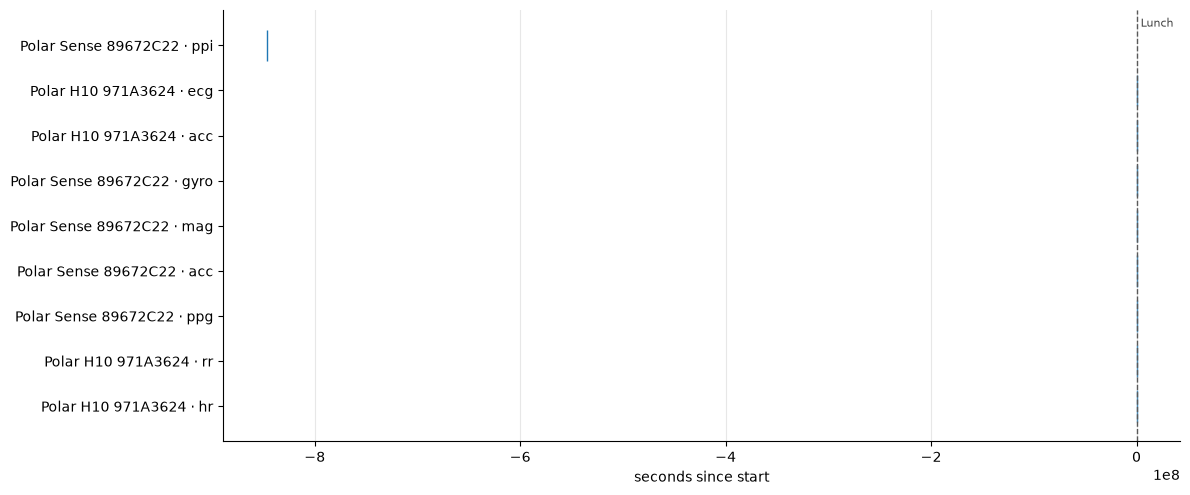

In [7]:
def coverage_plot(s, max_gap_s=1.0):
    keys = [k for k in s.streams if k[1] != "markers"]
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(keys) + 1))
    for i, key in enumerate(keys):
        df = s.streams[key]
        t = df["elapsed_s"].to_numpy()
        if not len(t):
            continue
        tol = max(max_gap_s, 3 * np.median(np.diff(t))) if len(t) > 1 else max_gap_s
        if key[1] in ("ppi", "rr"):
            tol = 3.0
        breaks = np.where(np.diff(t) > tol)[0]
        starts = np.r_[t[0], t[breaks + 1]]
        ends = np.r_[t[breaks], t[-1]]
        ax.broken_barh(list(zip(starts, ends - starts)), (i - 0.35, 0.7), color="C0")
    ax.set_yticks(range(len(keys)), [f"{s.device_name(d)} · {sig}" for d, sig in keys])
    add_markers(ax, s, elapsed=True, labels=True)
    ax.set_xlabel("seconds since start")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()

POINT_LABELS = {"Artifact"}   # markers that flag a moment instead of starting a new segment

def add_markers(ax, s, elapsed=False, labels=False):
    mk = s.get("markers")
    if mk is None:
        return
    for _, r in mk.iterrows():
        x = r["elapsed_s"] if elapsed else r["t"]
        point = r["label"] in POINT_LABELS
        ax.axvline(x, color="C3" if point else "0.35", ls=":" if point else "--", lw=1)
        if labels:
            ax.annotate(r["label"], (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -12),
                        textcoords="offset points", fontsize=8, color="0.25")

coverage_plot(S)

## 4. Everything on one timeline

Heart rate and per-sensor acceleration magnitude, aligned on the shared phone clock (`t`).

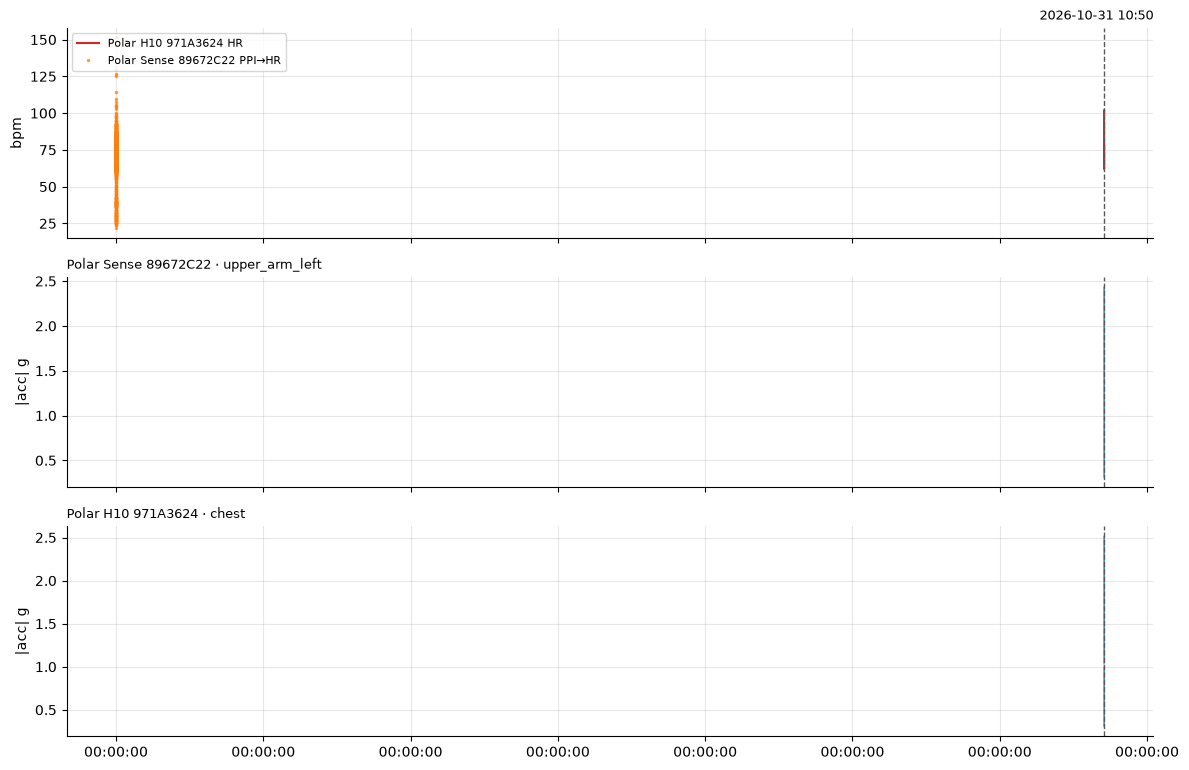

In [8]:
def acc_magnitude_g(df):
    return np.sqrt(df["x_mg"] ** 2 + df["y_mg"] ** 2 + df["z_mg"] ** 2) / 1000

def break_gaps(t, y, gap_s=1.0):
    # NaN at gaps so a line plot does not bridge a dropout.
    y = pd.Series(np.asarray(y, float), index=t)
    y[(pd.Series(t).diff().dt.total_seconds() > gap_s).to_numpy()] = np.nan
    return y

def overview_plot(s):
    acc_keys = [k for k in s.streams if k[1] == "acc"]
    fig, axes = plt.subplots(1 + len(acc_keys), 1, figsize=(12, 2.6 * (1 + len(acc_keys))), sharex=True)
    axes = np.atleast_1d(axes)
    for (dev, sig), df in s.streams.items():
        if sig == "hr":
            axes[0].plot(df["t"], df["hr_bpm"].where(df["hr_bpm"] > 0), label=f"{s.device_name(dev)} HR", color="C3")
        if sig == "ppi":
            ok = (df["blocker"] == 0) & (df["skin_contact"] != 0)
            axes[0].plot(df.loc[ok, "t"], 60000 / df.loc[ok, "ppi_ms"], ".", ms=3,
                         label=f"{s.device_name(dev)} PPI→HR", color="C1", alpha=0.7)
    axes[0].set_ylabel("bpm")
    axes[0].legend(loc="upper left", fontsize=8)
    for ax, key in zip(axes[1:], acc_keys):
        df = s.streams[key]
        ax.plot(break_gaps(df["t"], acc_magnitude_g(df)), lw=0.5)
        ax.set_ylabel("|acc| g")
        ax.set_title(f"{s.device_name(key[0])} · {s.placement(key[0])}", fontsize=9, loc="left")
    for ax in axes:
        add_markers(ax, s)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=s.tz))
    axes[0].set_title(f"{s.manifest.get('context', {}).get('subjectId') or ''}  {s.start.tz_convert(s.tz):%Y-%m-%d %H:%M}", loc="right", fontsize=9)
    plt.tight_layout()

overview_plot(S)

### Zoom in: ECG and PPG together

A few seconds of raw ECG (H10) and PPG (optical sensor) on the shared clock. Each pulse wave reaches the arm a little after the R peak (pulse arrival time, roughly 0.1 s to the foot of the pulse on the upper arm). In Polar raw PPG larger values mean more blood volume. Change `AT_S` to look elsewhere.

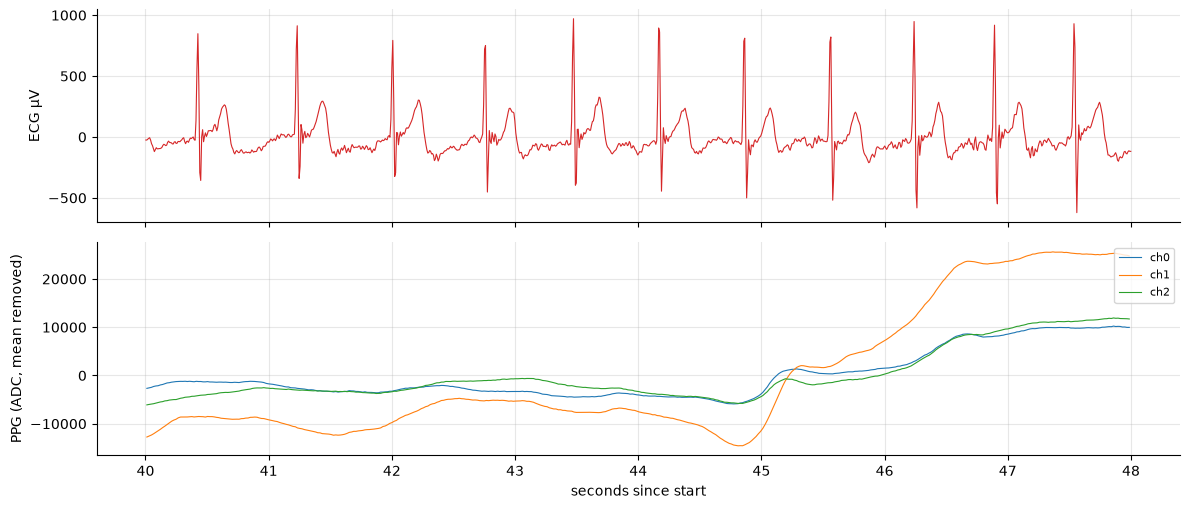

In [9]:
AT_S, WINDOW_S = 40, 8

def window(df, at, length):
    return df[(df["elapsed_s"] >= at) & (df["elapsed_s"] < at + length)]

ecg, ppg = S.get("ecg"), S.get("ppg")
panels = [x for x in (ecg, ppg) if x is not None]
if panels:
    fig, axes = plt.subplots(len(panels), 1, figsize=(12, 2.6 * len(panels)), sharex=True)
    axes = np.atleast_1d(axes)
    i = 0
    if ecg is not None:
        w = window(ecg, AT_S, WINDOW_S)
        axes[i].plot(w["elapsed_s"], w["ecg_uv"], lw=0.8, color="C3")
        axes[i].set_ylabel("ECG µV")
        i += 1
    if ppg is not None:
        w = window(ppg, AT_S, WINDOW_S)
        for c in [c for c in w.columns if c.startswith("ch")][:3]:
            axes[i].plot(w["elapsed_s"], w[c] - w[c].mean(), lw=0.8, label=c)  # larger = more blood
        axes[i].set_ylabel("PPG (ADC, mean removed)")
        axes[i].legend(fontsize=8, loc="upper right")
    axes[-1].set_xlabel("seconds since start")
    plt.tight_layout()

## 5. Segments from markers

Every marker starts a segment that lasts until the next one, except markers listed in `POINT_LABELS` (above: `Artifact`), which only flag a moment. The time before the first marker becomes `(start)`.

In [10]:
def segments(s):
    end = (pd.Timestamp(s.manifest["endedAt"]) - s.start).total_seconds() if s.manifest.get("endedAt") \
        else max(df["elapsed_s"].max() for df in s.streams.values() if len(df))
    mk = s.get("markers")
    rows = [("(start)", 0.0)]
    if mk is not None:
        rows += [(r["label"], r["elapsed_s"]) for _, r in mk.iterrows() if r["label"] not in POINT_LABELS]
    rows.sort(key=lambda r: r[1])
    seg = pd.DataFrame(rows, columns=["segment", "start_s"])
    seg["end_s"] = list(seg["start_s"].iloc[1:]) + [end]
    seg = seg[seg["end_s"] - seg["start_s"] > 1].reset_index(drop=True)
    seg["segment"] = [f"{i + 1}. {name}" for i, name in enumerate(seg["segment"])]
    return seg

SEG = segments(S)
SEG

,segment,start_s,end_s
0,1. (start),0.000,1047.357
1,2. Lunch,1047.357,1800.000


## 6. HRV

### Cleaning

Interval series always need cleaning before HRV:

* **RR (H10)**: keep 300–2000 ms and drop beats that differ more than 20 % from the local median (ectopic beats, missed detections).
* **PPI (Verity Sense, OH1, 360/Loop)**: additionally drop rows with `blocker == 1` (the sensor flags motion) or `skin_contact == 0`. PPI is only reliable at rest, and the first ~25 s after start contain no PPI.

Nothing is filtered in the files themselves; this is done here.

In [11]:
def clean_intervals(ms, rel_tol=0.20, window=11):
    ms = pd.Series(ms, dtype=float)
    ok = ms.between(300, 2000)
    med = ms.where(ok).rolling(window, center=True, min_periods=3).median()
    return ok & ((ms - med).abs() <= rel_tol * med)

def interval_series(s):
    # Clean NN-interval series per source: {name: DataFrame(elapsed_s, ms)}.
    out = {}
    rr = s.get("rr")
    if rr is not None and len(rr):
        # Beat times: within one notification the RR intervals end at its arrival time;
        # rebuild them backwards from there for sub-second timing.
        ends = rr.groupby("frame")["rx_unix_ms"].transform("first") - rr[::-1].groupby("frame")["rr_ms"].cumsum()[::-1] + rr["rr_ms"]
        df = pd.DataFrame({"elapsed_s": (ends * 1e6 - s.start.value) / 1e9, "ms": rr["rr_ms"].astype(float)})
        out[f"RR · {s.device_name(next(d for d, sig in s.streams if sig == 'rr'))}"] = df[clean_intervals(df["ms"]).to_numpy()]
    for (dev, sig), df in s.streams.items():
        if sig != "ppi" or not len(df):
            continue
        valid = (df["blocker"] == 0) & ((df["skin_contact"] != 0) | (df["skin_contact_supported"] == 0))
        d = df.loc[valid, ["elapsed_s", "ppi_ms"]].rename(columns={"ppi_ms": "ms"}).astype(float)
        out[f"PPI · {s.device_name(dev)}"] = d[clean_intervals(d["ms"]).to_numpy()]
    return out

NN = interval_series(S)
for name, df in NN.items():
    print(f"{name}: {len(df)} clean intervals")

RR · Polar H10 971A3624: 2301 clean intervals
PPI · Polar Sense 89672C22: 993 clean intervals


### Time and frequency domain

* **mean HR**, **SDNN** (overall variability), **RMSSD** and **pNN50** (beat-to-beat, vagal) per segment.
* **LF / HF** power (0.04–0.15 Hz / 0.15–0.4 Hz) from a 4 Hz-resampled tachogram with Welch's method. Only computed for segments of at least `MIN_FREQ_S` seconds; 5 minutes is the usual standard, so treat shorter windows as indicative only.

In [12]:
MIN_FREQ_S = 120

def hrv_time(ms):
    ms = np.asarray(ms, float)
    if len(ms) < 3:
        return {}
    d = np.diff(ms)
    return {"beats": len(ms), "mean HR": 60000 / ms.mean(), "SDNN ms": ms.std(ddof=1),
            "RMSSD ms": np.sqrt(np.mean(d ** 2)), "pNN50 %": 100 * np.mean(np.abs(d) > 50)}

def hrv_freq(t_s, ms, fs=4.0):
    if len(ms) < 10 or t_s[-1] - t_s[0] < MIN_FREQ_S:
        return {}
    grid = np.arange(t_s[0], t_s[-1], 1 / fs)
    tach = np.interp(grid, t_s, ms)
    f, p = signal.welch(tach - tach.mean(), fs=fs, nperseg=min(len(grid), int(fs * 120)))
    trapz = getattr(np, "trapezoid", None) or np.trapz   # NumPy 2 renamed trapz
    band = lambda lo, hi: trapz(p[(f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)])
    lf, hf = band(0.04, 0.15), band(0.15, 0.40)
    return {"LF ms²": lf, "HF ms²": hf, "LF/HF": lf / hf if hf else np.nan}

def hrv_table(nn, seg):
    rows = []
    for name, df in nn.items():
        whole = [("(whole log)", df["elapsed_s"].min(), df["elapsed_s"].max() + 1)]
        for label, a, b in whole + list(seg[["segment", "start_s", "end_s"]].itertuples(index=False)):
            w = df[(df["elapsed_s"] >= a) & (df["elapsed_s"] < b)]
            row = {"source": name, "segment": label, **hrv_time(w["ms"]),
                   **hrv_freq(w["elapsed_s"].to_numpy(), w["ms"].to_numpy())}
            rows.append(row)
    return pd.DataFrame(rows).round(1)

HRV = hrv_table(NN, SEG)
HRV

,source,segment,beats,mean HR,SDNN ms,RMSSD ms,pNN50 %,LF ms²,HF ms²,LF/HF
0,RR · Polar H10 971A3624,(whole log),2301.0,77.0,92.7,34.8,9.9,2027.0,330.8,6.1
1,RR · Polar H10 971A3624,1. (start),1368.0,79.0,80.9,34.5,9.9,2032.3,364.5,5.6
2,RR · Polar H10 971A3624,2. Lunch,933.0,74.4,101.6,35.3,9.9,2128.4,309.7,6.9
3,PPI · Polar Sense 89672C22,(whole log),993.0,71.7,130.5,95.8,40.6,NaN,NaN,NaN
4,PPI · Polar Sense 89672C22,1. (start),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,PPI · Polar Sense 89672C22,2. Lunch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


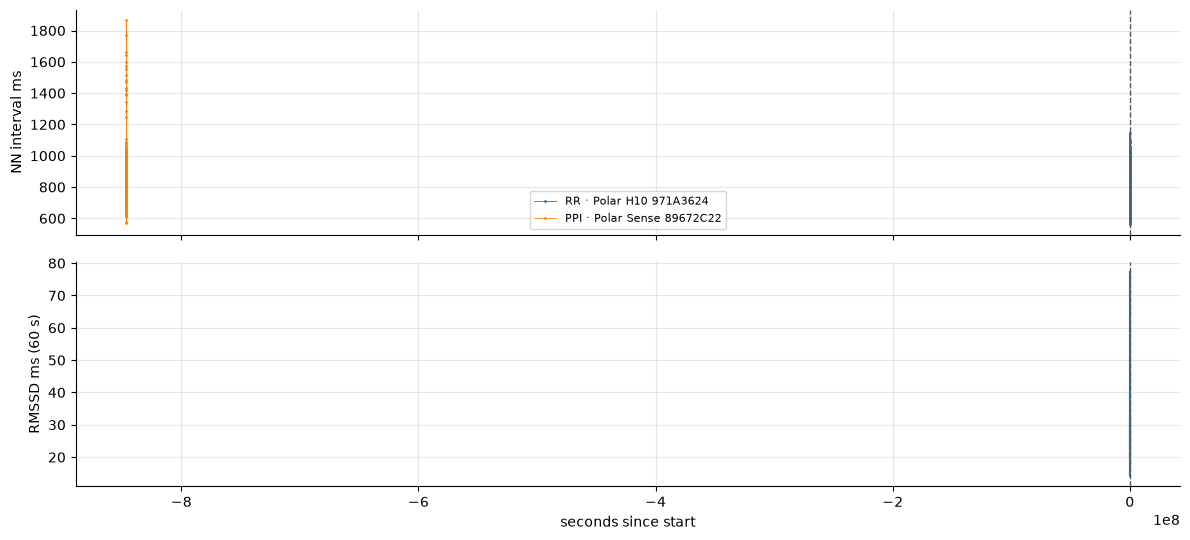

In [13]:
def rolling_rmssd(df, window_s=60, step_s=5):
    t, ms = df["elapsed_s"].to_numpy(), df["ms"].to_numpy()
    centers = np.arange(t.min() + window_s / 2, t.max() - window_s / 2, step_s)
    vals = [hrv_time(ms[(t >= c - window_s / 2) & (t < c + window_s / 2)]).get("RMSSD ms", np.nan) for c in centers]
    return centers, np.array(vals)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for name, df in NN.items():
    axes[0].plot(df["elapsed_s"], df["ms"], ".-", ms=2, lw=0.6, label=name)
    c, v = rolling_rmssd(df)
    axes[1].plot(c, v, label=name)
axes[0].set_ylabel("NN interval ms"); axes[0].legend(fontsize=8)
axes[1].set_ylabel("RMSSD ms (60 s)"); axes[1].set_xlabel("seconds since start")
for ax in axes:
    add_markers(ax, S, elapsed=True)
plt.tight_layout()

## 7. ECG R-peaks

A simple detector: 5–20 Hz band-pass, then peaks at least 300 ms apart and above an adaptive threshold. The heart rate from the detected peaks is compared with the HR the H10 itself reported. For publication-grade work use a dedicated library such as [NeuroKit2](https://neuropsychology.github.io/NeuroKit/) on the same `ecg_uv` column.

2309 R-peaks at 130 Hz


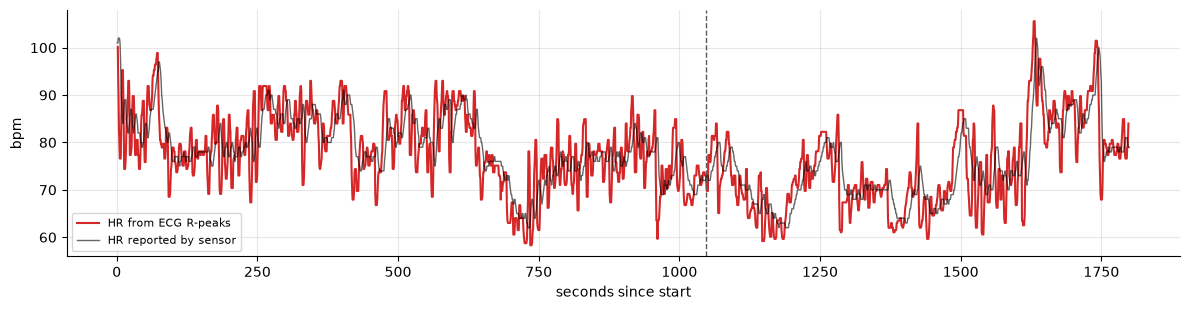

In [14]:
def detect_r_peaks(ecg, fs=None):
    t = ecg["elapsed_s"].to_numpy()
    fs = fs or 1 / np.median(np.diff(t))
    b, a = signal.butter(3, [5, 20], btype="band", fs=fs)
    x = signal.filtfilt(b, a, ecg["ecg_uv"].to_numpy(float))
    env = np.abs(x)
    thr = pd.Series(env).rolling(int(2 * fs), center=True, min_periods=1).max().to_numpy() * 0.45
    peaks, _ = signal.find_peaks(env, distance=int(0.3 * fs))
    peaks = peaks[env[peaks] > thr[peaks]]
    return t[peaks], fs

if ecg is not None:
    r_t, fs = detect_r_peaks(ecg)
    ecg_hr = pd.Series(60 / np.diff(r_t), index=r_t[1:])
    print(f"{len(r_t)} R-peaks at {fs:.0f} Hz")
    fig, ax = plt.subplots()
    ax.plot(ecg_hr.index, ecg_hr.rolling(5, center=True).median(), label="HR from ECG R-peaks", color="C3")
    hr = S.get("hr", next(d for d, sig in S.streams if sig == "ecg"))   # HR of the same sensor
    if hr is not None:
        ax.plot(hr["elapsed_s"], hr["hr_bpm"].where(hr["hr_bpm"] > 0), label="HR reported by sensor", color="k", lw=1, alpha=0.6)
    add_markers(ax, S, elapsed=True)
    ax.set_ylabel("bpm"); ax.set_xlabel("seconds since start"); ax.legend(fontsize=8)
    plt.tight_layout()

## 8. Activity

From each accelerometer: **ENMO** (Euclidean norm minus one g, negatives set to 0), a standard movement intensity measure in mg, and the **dominant movement frequency** (e.g. step or pedalling cadence) per segment.

In [15]:
def activity_table(s, seg):
    rows = []
    for (dev, sig), df in s.streams.items():
        if sig != "acc":
            continue
        mag = acc_magnitude_g(df).to_numpy()
        t = df["elapsed_s"].to_numpy()
        fs = 1 / np.median(np.diff(df["sensor_ts_ns"].to_numpy()) / 1e9)
        for label, a, b in seg[["segment", "start_s", "end_s"]].itertuples(index=False):
            m = (t >= a) & (t < b)
            if m.sum() < fs * 4:
                continue
            x = mag[m] - mag[m].mean()
            f, p = signal.welch(x, fs=fs, nperseg=min(len(x), int(fs * 8)))
            band = (f > 0.5) & (f < 5)
            rows.append({"device": s.device_name(dev), "placement": s.placement(dev), "segment": label,
                         "ENMO mg": 1000 * np.clip(mag[m] - 1, 0, None).mean(),
                         "SD |acc| mg": 1000 * mag[m].std(),
                         # cadence only where there is real movement
                         "dominant Hz": f[band][np.argmax(p[band])] if band.any() and mag[m].std() > 0.05 else np.nan})
    return pd.DataFrame(rows).round(2)

ACT = activity_table(S, SEG)
ACT

,device,placement,segment,ENMO mg,SD |acc| mg,dominant Hz
0,Polar Sense 89672C22,upper_arm_left,1. (start),24.10,86.22,1.88
1,Polar Sense 89672C22,upper_arm_left,2. Lunch,14.79,46.47,NaN
2,Polar H10 971A3624,chest,1. (start),13.22,87.54,1.88
3,Polar H10 971A3624,chest,2. Lunch,5.81,47.73,NaN


## 9. Export a 1-second feature table

One row per second on the shared clock: heart rate, instantaneous NN-interval HR per source, ENMO per accelerometer and the current segment. This is a convenient starting point for statistics or for joining with other data.

In [16]:
def feature_table(s, seg, nn):
    end = int(np.ceil(seg["end_s"].max()))
    out = pd.DataFrame({"elapsed_s": np.arange(0, end)})
    out["time"] = s.start.tz_convert(s.tz) + pd.to_timedelta(out["elapsed_s"], unit="s")
    sec = lambda df: np.floor(df["elapsed_s"]).astype(int)
    for (dev, sig), df in s.streams.items():
        if sig == "hr":
            out = out.merge(df.assign(elapsed_s=sec(df)).groupby("elapsed_s")["hr_bpm"].mean()
                            .rename(f"hr_bpm_{dev}"), on="elapsed_s", how="left")
        if sig == "acc":
            enmo = df.assign(elapsed_s=sec(df), enmo=1000 * np.clip(acc_magnitude_g(df) - 1, 0, None))
            out = out.merge(enmo.groupby("elapsed_s")["enmo"].mean().rename(f"enmo_mg_{dev}"), on="elapsed_s", how="left")
    for name, df in nn.items():
        col = "nn_hr_" + name.split(" · ")[0].lower()
        out = out.merge(df.assign(elapsed_s=sec(df), v=60000 / df["ms"]).groupby("elapsed_s")["v"].mean()
                        .rename(col), on="elapsed_s", how="left")
    idx = np.searchsorted(seg["start_s"].to_numpy(), out["elapsed_s"].to_numpy(), side="right") - 1
    out["segment"] = seg["segment"].to_numpy()[np.clip(idx, 0, len(seg) - 1)]
    return out

FEATURES = feature_table(S, SEG, NN)
out_dir = Path("analysis_out"); out_dir.mkdir(exist_ok=True)
FEATURES.to_csv(out_dir / f"{S.path.name}_features_1s.csv", index=False)
HRV.to_csv(out_dir / f"{S.path.name}_hrv.csv", index=False)
ACT.to_csv(out_dir / f"{S.path.name}_activity.csv", index=False)
print("written to", out_dir)
FEATURES.head()

written to analysis_out


,elapsed_s,time,hr_bpm_971A3624,enmo_mg_89672C22,enmo_mg_971A3624,nn_hr_rr,nn_hr_ppi,segment
0,0,2026-10-31 10:50:00+02:00,101.0,48.905967,26.389750,100.089042,NaN,1. (start)
1,1,2026-10-31 10:50:01+02:00,101.0,16.136117,13.437972,103.806539,NaN,1. (start)
2,2,2026-10-31 10:50:02+02:00,102.0,20.253430,3.596488,104.166667,NaN,1. (start)
3,3,2026-10-31 10:50:03+02:00,102.0,17.267792,1.851923,100.421856,NaN,1. (start)
4,4,2026-10-31 10:50:04+02:00,102.0,16.180374,2.213503,94.339623,NaN,1. (start)


---

**Notes**

* Units: ECG µV, acceleration mG, gyroscope °/s, magnetometer gauss, PPG raw ADC counts (not calibrated), temperature °C, pressure bar. Each stream's settings as negotiated with the sensor are in `session.json › streams[].settings`.
* `rx_unix_ms` is when the phone received a Bluetooth frame. All rows of one frame share it, so use `sensor_ts_ns` (or `t`) for sample timing and `rx_unix_ms` only for alignment.
* Several logs: `[load_session(p.parent) for p in Path("logs").glob("*/session.json")]` and concatenate the tables above with a `log` column.

SensorForge · <https://sensorforge.app> · This notebook is MIT licensed — copy, change and share it.